# Домашнее задание 1. Amazon Beauty 5-core

Ноутбук сравнивает пять своих моделей на персональных top-10.
Рекомендуем товар категории Beauty.
Релевантный товар на validation и test имеет оценку не ниже 4.
Этот критерий один для всех моделей.

Запуск. Откройте каталог с ноутбуком, выберите ядро Python (recsys) и выполните ячейки сверху вниз.
Ноутбук сам скачает отзывы и метаданные в `data/`.
Зерно равно 42.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd().resolve()
if not (ROOT / "models").exists():
    nested = ROOT / "hw1" / "submission"
    if (nested / "models").exists():
        ROOT = nested.resolve()
sys.path.insert(0, str(ROOT))

from pipeline import (
    K,
    MIN_USER_REVIEWS,
    RELEVANT_RATING,
    SEED,
    SOURCE_PAGE,
    aggregate_reviews,
    attach_categories,
    build_matrices,
    ensure_data,
    keep_active_users,
    load_meta,
    load_reviews,
    quality_report,
    select_and_test,
    sparsity,
    temporal_split,
)

np.random.seed(SEED)
DATA = ROOT / "data"
print("Каталог ноутбука:", ROOT)


Каталог ноутбука: /Users/vorobevd/techHub/Edu/recsys/hw1/submission


## 1. Данные

Источник: Amazon Reviews, подвыборка Beauty 5-core.
Страница: https://mcauleylab.ucsd.edu/public_datasets/data/amazon/datasets.html

Отзыв хранит пользователя `reviewerID`, товар `asin`, оценку `overall` от 1 до 5, время `unixReviewTime` и голоса `helpful`.
Метаданные хранят `asin`, название и путь категории.
В модель факторной машины идёт второй уровень категории. Он известен до рекомендации.
Оценку и голоса `helpful` в признаки не кладём.
Голоса используем только в обучающем таргете пятой модели.


In [3]:
reviews_path, meta_path = ensure_data(DATA)
reviews = load_reviews(reviews_path)
meta = load_meta(meta_path)
print("Страница источника:", SOURCE_PAGE)
print("Файл отзывов:", reviews_path.name)
print("Файл метаданных:", meta_path.name)
print("Строк отзывов:", reviews.height)
print("Пользователей:", reviews["user_id"].n_unique())
print("Товаров:", reviews["item_id"].n_unique())
print("Строк метаданных:", meta.height)
print(reviews.head(3))


Страница источника: https://mcauleylab.ucsd.edu/public_datasets/data/amazon/datasets.html
Файл отзывов: reviews_Beauty_5.json.gz
Файл метаданных: meta_Beauty.json.gz
Строк отзывов: 198502
Пользователей: 22363
Товаров: 12101
Строк метаданных: 259204
shape: (3, 5)
┌────────────────┬────────────┬────────┬────────────┬────────────┐
│ user_id        ┆ item_id    ┆ rating ┆ timestamp  ┆ helpful_up │
│ ---            ┆ ---        ┆ ---    ┆ ---        ┆ ---        │
│ str            ┆ str        ┆ f64    ┆ i64        ┆ f64        │
╞════════════════╪════════════╪════════╪════════════╪════════════╡
│ A1YJEY40YUW4SE ┆ 7806397051 ┆ 1.0    ┆ 1391040000 ┆ 3.0        │
│ A60XNB876KYML  ┆ 7806397051 ┆ 3.0    ┆ 1397779200 ┆ 1.0        │
│ A3G6XNM240RMWA ┆ 7806397051 ┆ 4.0    ┆ 1378425600 ┆ 0.0        │
└────────────────┴────────────┴────────┴────────────┴────────────┘


## 2. EDA и подготовка

Сначала считаем пропуски и дубликаты сырой таблицы.
Повторная пара пользователь–товар схлопывается в одну строку.
Оценка равна среднему. Время равно максимуму. Голоса `helpful` берутся у самого позднего отзыва.
В этих данных таких пар нет, поэтому объём не меняется.
Оставляем пользователей, у которых не меньше 5 отзывов.
Здесь таких пользователей нет: файл уже 5-core.
Подвыборку не делаем. 198 502 взаимодействия уже лежат внутри лимита от 100 000 до 2 000 000.
Категорию товара присоединяем слева. Пустая категория получает метку `unknown`.
Гистограммы активности и разреженность считаем на очищенной таблице.


In [5]:
report = quality_report(reviews)
print("Пропуски по столбцам:", report["nulls"])
print("Полных дублей строк:", report["full_duplicate_rows"])
print("Лишних строк с тем же пользователем и товаром:", report["user_item_duplicate_rows"])
print("Исходный объём:", report["rows"], "отзывов,", report["users"], "пользователей,", report["items"], "товаров")


Пропуски по столбцам: {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0, 'helpful_up': 0}
Полных дублей строк: 0
Лишних строк с тем же пользователем и товаром: 0
Исходный объём: 198502 отзывов, 22363 пользователей, 12101 товаров


In [6]:
interactions = keep_active_users(aggregate_reviews(reviews), MIN_USER_REVIEWS)
interactions = attach_categories(interactions, meta)
n_users = interactions["user_id"].n_unique()
n_items = interactions["item_id"].n_unique()
known = interactions.filter(pl.col("category") != "unknown").height / interactions.height
print("После очистки:", interactions.height, "взаимодействий")
print("Пользователей:", n_users)
print("Товаров:", n_items)
print("Разреженность:", round(sparsity(interactions.height, n_users, n_items), 6))
print("Доля строк с известной категорией:", round(known, 4))
print("Категорий:", interactions["category"].n_unique())
print(interactions["rating"].value_counts().sort("rating"))


После очистки: 198502 взаимодействий
Пользователей: 22363
Товаров: 12101
Разреженность: 0.999266
Доля строк с известной категорией: 1.0
Категорий: 6
shape: (5, 2)
┌────────┬────────┐
│ rating ┆ count  │
│ ---    ┆ ---    │
│ f64    ┆ u32    │
╞════════╪════════╡
│ 1.0    ┆ 10526  │
│ 2.0    ┆ 11456  │
│ 3.0    ┆ 22248  │
│ 4.0    ┆ 39741  │
│ 5.0    ┆ 114531 │
└────────┴────────┘


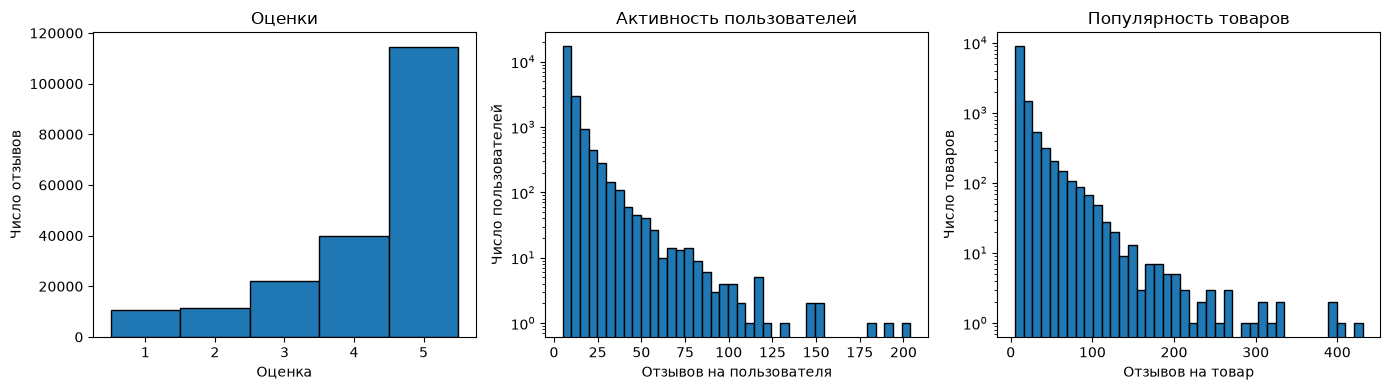

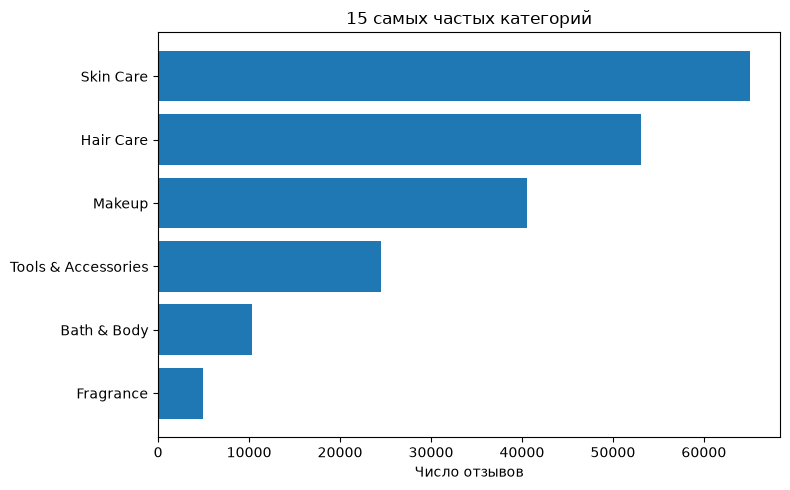

In [7]:
user_counts = interactions.group_by("user_id").len()["len"].to_numpy()
item_counts = interactions.group_by("item_id").len()["len"].to_numpy()
top_categories = (
    interactions.group_by("category")
    .len()
    .sort("len", descending=True)
    .head(15)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(interactions["rating"].to_numpy(), bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor="black")
axes[0].set_xlabel("Оценка")
axes[0].set_ylabel("Число отзывов")
axes[0].set_title("Оценки")
axes[1].hist(user_counts, bins=40, edgecolor="black")
axes[1].set_yscale("log")
axes[1].set_xlabel("Отзывов на пользователя")
axes[1].set_ylabel("Число пользователей")
axes[1].set_title("Активность пользователей")
axes[2].hist(item_counts, bins=40, edgecolor="black")
axes[2].set_yscale("log")
axes[2].set_xlabel("Отзывов на товар")
axes[2].set_ylabel("Число товаров")
axes[2].set_title("Популярность товаров")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_categories["category"].to_list()[::-1], top_categories["len"].to_list()[::-1])
ax.set_xlabel("Число отзывов")
ax.set_title("15 самых частых категорий")
fig.tight_layout()
plt.show()


## 3. Протокол оценки

Зерно равно 42.
У каждого пользователя последний по времени отзыв идёт в test.
Предпоследний отзыв идёт в validation.
Остальные отзывы идут в train.
Кандидаты — весь каталог.
Из top-10 убираем товары train.
На test дополнительно убираем товар validation.
Холодного пользователя в test нет. У каждого пользователя в train остаётся не меньше трёх отзывов.
Новый товар остаётся в каталоге. У него нет строки в train, поэтому соседи и факторы для него пустые.
В метрику входят пользователи, у которых отложенный товар имеет оценку не ниже 4.
Основную метрику выбираем до подбора. Это NDCG@10.
У пользователя один релевантный товар. NDCG@10 больше, если этот товар стоит выше в top-10.
Вторая метрика на test — HitRate@10.
HitRate@10 показывает, попал ли этот товар в десять показанных позиций.
Обе метрики отвечают на вопрос персонального top-10.
Подбор идёт по validation. Test считаем один раз у выбранных параметров.
Модель учится только на train.


In [9]:
train, validation, test = temporal_split(interactions)
print("Train:", train.height)
print("Validation:", validation.height)
print("Test:", test.height)
print("Порог релевантности:", RELEVANT_RATING)
print("K:", K)
bundle = build_matrices(train, validation, test)
print("Пользователей в индексах:", bundle["n_users"])
print("Товаров в каталоге:", bundle["n_items"])
print("Категорий в FM:", bundle["n_cats"])
print("Пользователей в validation с релевантным товаром:", len(bundle["val_eval"][0]))
print("Пользователей в test с релевантным товаром:", len(bundle["test_eval"][0]))


Train: 153776
Validation: 22363
Test: 22363
Порог релевантности: 4.0
K: 10
Пользователей в индексах: 22363
Товаров в каталоге: 12101
Категорий в FM: 6
Пользователей в validation с релевантным товаром: 17158
Пользователей в test с релевантным товаром: 17267


## 4. Модели и пространство поиска

Все модели пишут свои обучение, скор и top-10.
Библиотеки готовых рекомендательных моделей не используются.

Item-kNN. Косинус товаров считается по столбцам матрицы оценок.
У товара $i$ остаётся $k$ соседей с положительным косинусом. Эти веса лежат в строке матрицы $S$.
Скор пользователя равен $x_u S$.
В сумму для товара $i$ входят те товары истории $j$, у которых $i$ стоит среди соседей $j$.
Сетка: k = 20 и k = 50. Соседей 50 считаем один раз.

Явный ALS. Прогноз $\hat r_{ui} = p_u^\top q_i$.
По наблюдаемым оценкам минимизируется

$$\sum_{(u,i)\in\Omega}(r_{ui}-p_u^\top q_i)^2+\lambda\Big(\sum_u\|p_u\|^2+\sum_i\|q_i\|^2\Big).$$

При фиксированных $q$ шаг пользователя равен $(Q_u^\top Q_u+\lambda I)^{-1}Q_u^\top r_u$.
Шаг товара симметричен.
Сетка: ранг 16 и 32. Регуляризация 0.1. Итераций 10.

EASE. $X$ содержит оценки, пустая пара равна нулю.
$P=(X^\top X+\lambda I)^{-1}$.
Вес $B_{ij}$ равен 0 на диагонали и $-P_{ij}/P_{ii}$ вне диагонали.
Скор равен $x_u B$.
Сетка: lambda = 50 и lambda = 500. Матрицу Грама считаем один раз.

FM. Признаки — id пользователя, id товара и категория товара.
Категория известна до рекомендации. Оценка и `helpful` в признаки не входят.
Прогноз

$$\hat r = w_0+w_u+w_i+w_c+\langle v_u,v_i\rangle+\langle v_u,v_c\rangle+\langle v_i,v_c\rangle.$$

Обучение минимизирует средний квадрат ошибки по отзывам train.
Точка поиска: ранг 16, 5 эпох Adam, lr = 0.01, батч 4096, CPU.

Пятая модель использует тот же ALS. Меняется цель обучения:

$$z_{ui}=r_{ui}\bigl(1+\log(1+h_{ui})\bigr).$$

$h_{ui}$ — число голосов «полезно».
Отзыв, который другие отметили как полезный, даёт более сильный обучающий сигнал, чем сырая оценка.
Это не вес confidence при той же единичной матрице.
На test релевантность прежняя: оценка не ниже 4.
Ранг берём у победителя базового ALS. Отдельную сетку ранга не строим.


In [11]:
results, chosen = select_and_test(bundle)
print("Выбранные параметры:")
for name, params in chosen.items():
    print(f"{name}: {params}")


ItemKNN k=50 validation NDCG@10=0.0398
ItemKNN k=20 validation NDCG@10=0.0385
ALS rank=16, reg=0.1, iters=10 validation NDCG@10=0.0005
ALS rank=32, reg=0.1, iters=10 validation NDCG@10=0.0028
EASE lambda=50 validation NDCG@10=0.0226
EASE lambda=500 validation NDCG@10=0.0464
FM rank=16, epochs=5, lr=0.01, batch=4096 validation NDCG@10=0.0002
ALSCustom rank=32, reg=0.1, iters=10, target=rating*(1+log1p(helpful)) validation NDCG@10=0.0013
Выбранные параметры:
ItemKNN: k=50
ALS: rank=32, reg=0.1, iters=10
EASE: lambda=500
FM: rank=16, epochs=5, lr=0.01, batch=4096
ALSCustom: rank=32, reg=0.1, iters=10, target=rating*(1+log1p(helpful))


## 5. Сравнение

Таблица validation показывает все точки сетки.
Таблица test показывает только выбранные параметры.
Обе метрики считаются при K = 10.


In [13]:
validation_table = (
    results.filter(pl.col("split") == "validation")
    .select(["model", "params", "NDCG@10", "HitRate@10", "users"])
    .sort(["model", "NDCG@10"], descending=[False, True])
)
test_table = (
    results.filter(pl.col("split") == "test")
    .select(["model", "params", "NDCG@10", "HitRate@10", "users"])
    .sort("NDCG@10", descending=True)
)
print("Validation")
print(validation_table)
print("Test")
print(test_table)


Validation
shape: (8, 5)
┌───────────┬─────────────────────────────────┬──────────┬────────────┬───────┐
│ model     ┆ params                          ┆ NDCG@10  ┆ HitRate@10 ┆ users │
│ ---       ┆ ---                             ┆ ---      ┆ ---        ┆ ---   │
│ str       ┆ str                             ┆ f64      ┆ f64        ┆ i64   │
╞═══════════╪═════════════════════════════════╪══════════╪════════════╪═══════╡
│ ALS       ┆ rank=32, reg=0.1, iters=10      ┆ 0.002786 ┆ 0.006003   ┆ 17158 │
│ ALS       ┆ rank=16, reg=0.1, iters=10      ┆ 0.000542 ┆ 0.001107   ┆ 17158 │
│ ALSCustom ┆ rank=32, reg=0.1, iters=10, ta… ┆ 0.001342 ┆ 0.003089   ┆ 17158 │
│ EASE      ┆ lambda=500                      ┆ 0.046413 ┆ 0.07868    ┆ 17158 │
│ EASE      ┆ lambda=50                       ┆ 0.022644 ┆ 0.038874   ┆ 17158 │
│ FM        ┆ rank=16, epochs=5, lr=0.01, ba… ┆ 0.00019  ┆ 0.000408   ┆ 17158 │
│ ItemKNN   ┆ k=50                            ┆ 0.039824 ┆ 0.068714   ┆ 17158 │
│ ItemKNN   ┆ k

## 6. Выводы

На test лучший NDCG@10 у EASE с lambda = 500. Значение равно 0.0310. HitRate@10 равен 0.0535.
Item-kNN с k = 50 стоит вторым. NDCG@10 равен 0.0260. HitRate@10 равен 0.0456.
Явный ALS с рангом 32 сильно слабее. NDCG@10 равен 0.0019.
ALS со своим таргетом rating * (1 + log(1 + helpful)) получил NDCG@10 0.0011. Этот таргет не обогнал базовый ALS.
FM с категорией товара получил NDCG@10 0.0003. Пяти эпох на квадратичной ошибке не хватило, чтобы поднять один релевантный товар в top-10 из 12 101 кандидата.
В test вошло 17 267 пользователей. У каждого отложенный товар имеет оценку не ниже 4.

Ограничение эксперимента — полный каталог из 12 101 товара и один релевантный товар на пользователя.
Квадрат ошибки по сырым оценкам плохо поднимает этот товар в top-10.
Поэтому ALS и FM сильно ниже EASE и item-kNN.
Сетка FM состоит из одной точки. Пяти эпох мало.


In [15]:
best = test_table.row(0, named=True)
als = test_table.filter(pl.col("model") == "ALS").row(0, named=True)
custom = test_table.filter(pl.col("model") == "ALSCustom").row(0, named=True)
fm = test_table.filter(pl.col("model") == "FM").row(0, named=True)
print(f"На test наибольший NDCG@10 у {best['model']}: {best['NDCG@10']:.4f}.")
print(f"Его HitRate@10 равен {best['HitRate@10']:.4f}.")
print(f"Параметры победителя: {best['params']}.")
print(f"Базовый ALS получил NDCG@10 {als['NDCG@10']:.4f} и HitRate@10 {als['HitRate@10']:.4f}.")
print(
    "ALS со своим таргетом rating * (1 + log1p(helpful)) получил "
    f"NDCG@10 {custom['NDCG@10']:.4f} и HitRate@10 {custom['HitRate@10']:.4f}."
)
print(f"Разница NDCG@10, ALSCustom минус ALS: {custom['NDCG@10'] - als['NDCG@10']:+.4f}.")
print(f"FM с категорией товара получил NDCG@10 {fm['NDCG@10']:.4f} и HitRate@10 {fm['HitRate@10']:.4f}.")
print("Модели ранжируют весь каталог. Уже известные товары в top-10 не входят.")
print(f"В test вошло {int(best['users'])} пользователей с оценкой отложенного товара не ниже 4.")


На test наибольший NDCG@10 у EASE: 0.0310.
Его HitRate@10 равен 0.0535.
Параметры победителя: lambda=500.
Базовый ALS получил NDCG@10 0.0019 и HitRate@10 0.0044.
ALS со своим таргетом rating * (1 + log1p(helpful)) получил NDCG@10 0.0011 и HitRate@10 0.0024.
Разница NDCG@10, ALSCustom минус ALS: -0.0008.
FM с категорией товара получил NDCG@10 0.0003 и HitRate@10 0.0009.
Модели ранжируют весь каталог. Уже известные товары в top-10 не входят.
В test вошло 17267 пользователей с оценкой отложенного товара не ниже 4.
